# Machine Learning – Milestone 1: Problem Definition & Data Pre-processing

**Problem:** predicting 30-day hospital readmission of diabetic patients (binary classification)
**Dataset:** *Diabetes 130-US Hospitals for Years 1999–2008*, UCI Machine Learning Repository (ID 296)
**Student ID:** SH2301468  |  **Personalisation seed:** `SEED = 2301468` (the digits of the student ID)

**Personalisation method (stated once here, repeated in the report):** the working dataset is a
**stratified 80 % subsample of patients** (not rows), drawn with
`train_test_split(..., train_size=0.8, stratify=<patient-level label>, random_state=2301468)`.
All encounters of a selected patient are kept. Every number in this notebook comes from this subsample,
never from the full public file.

## Introduction

### The problem
When a patient with diabetes leaves hospital and is back within a month, it usually means something in their care did not hold.
Early readmission is costly for hospitals and harmful for patients: the dataset's own documentation points out that poor diabetes care
raises hospital costs through repeat admissions and worsens illness and mortality for the patients concerned. If a hospital could flag,
at the moment of discharge, the patients most likely to return within 30 days, it could direct follow-up calls, medication reviews or home
support to the people who need them most.

**Task (binary classification).** Given the record of one hospital stay (demographics, length of stay, number of lab tests and
procedures, diagnoses, medications), predict whether the patient is **readmitted within 30 days of discharge (1) or not (0)**.

### The dataset
| | |
|---|---|
| **Name** | Diabetes 130-US Hospitals for Years 1999-2008 |
| **Source** | UCI Machine Learning Repository, dataset ID 296 (donated 2014): https://archive.ics.uci.edu/dataset/296 |
| **Collected** | Ten years (1999-2008) of clinical care at 130 US hospitals and integrated delivery networks |
| **Size** | 101,766 hospital encounters, 50 columns (47 features, 2 identifiers, 1 outcome) |
| **Unit of observation** | One hospital stay of a patient diagnosed with diabetes (the same patient can appear in several rows) |
| **Original outcome** | `readmitted`: `<30` (within 30 days), `>30` (after 30 days), `NO` (no record of readmission) |
| **Target used here** | `1` if `<30`, otherwise `0` |

### How the assignment requirements are met
| Requirement | How it is met |
|---|---|
| Real-world, non-toy, non-synthetic data | Genuine clinical records from 130 hospitals; not a scikit-learn bundled dataset and not generated |
| At least 1,000 samples after pre-processing | 101,766 encounters in the public file; 79,365 remain after personalised subsampling and cleaning |
| Personalised, seeded subsample | Stratified 80 % of patients, `random_state = 2301468` (digits of ID SH2301468); a fingerprint of the chosen patients is printed in Section 3 |
| Data that lets pre-processing skills be shown | Missing values coded as `?` (weight is about 97 % missing), hidden "not performed" categories, 700+ distinct diagnosis codes per column, heavy outliers in visit counts, repeated patients, mixed numeric and categorical features |
| Python 3 | Yes (versions printed in Section 1) |

### Why the problem is difficult
* **Imbalance.** Only about 11 % of encounters are 30-day readmissions (roughly 1 in 9), so a model that always predicts "no readmission" would be about 89 % accurate and useless. Evaluation must rely on recall, precision, F1 and PR-AUC.
* **Limited signal.** Readmission depends on things hospital records do not contain, such as support at home and whether the patient takes their medication, so near-perfect performance should not be expected.
* **Repeated patients.** A random split of rows would put the same person in both train and test and inflate results; the split must be done by patient.

### Ethical considerations
The data include age, gender and race. The work here is for coursework on prediction, not for deciding who receives care. Race is never guessed:
where it is missing it becomes its own "Missing" category instead of being imputed, and later milestones should check whether the final model
performs differently across groups.

### Scope and plan
**This milestone** covers problem framing, the personalised subsample, exploratory analysis and pre-processing, and it ends with saved training and test matrices.
**Later milestones** will train and compare several classification algorithms, tune them with cross-validation that groups by patient inside the
training data only, and report recall, precision, F1, PR-AUC and ROC-AUC on the untouched test set.

### References
* Strack, B., DeShazo, J. P., Gennings, C., Olmo, J. L., Ventura, S., Cios, K. J. and Clore, J. N. (2014). *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records.* BioMed Research International.
* Strack, B. et al. (2014). *Diabetes 130-US Hospitals for Years 1999-2008* [Dataset]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/296

---
## 1. Setup
*Analogy:* the seed is the fixed shuffle of a deck of cards. Anyone who starts from the same deck
and the same shuffle gets exactly the same hand, which is what makes the work reproducible.

In [1]:
import hashlib, os, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)

STUDENT_ID = "SH2301468"
SEED = int("".join(ch for ch in STUDENT_ID if ch.isdigit()))   # SH2301468 -> 2301468
SUBSAMPLE_FRACTION = 0.80
DATA_PATH = "diabetic_data.csv"        # from the UCI zip (also contains IDs_mapping.csv)
np.random.seed(SEED)

print("Student ID :", STUDENT_ID)
print("SEED       :", SEED)
print("Python     :", platform.python_version())
print("numpy      :", np.__version__)
print("pandas     :", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Student ID : SH2301468
SEED       : 2301468
Python     : 3.11.9
numpy      : 2.4.4
pandas     : 3.0.2
scikit-learn: 1.8.0


## 2. Loading the data (and a trap to avoid)
In this file, the text `?` means "missing", but the text `None` in `max_glu_serum` and `A1Cresult` means
"the test was **not performed**", which is a real clinical category, not a missing value.
Recent pandas versions (the one used here is printed in Section 1) treat the string `"None"` as `NaN` by default.
If we used the defaults we would wrongly create tens of thousands of fake missing values (the output below shows how many),
so we switch the defaults off and declare `?` ourselves.

In [2]:
default_read = pd.read_csv(DATA_PATH, usecols=["max_glu_serum", "A1Cresult"])
raw = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=["?"], low_memory=False)

print("NaN in max_glu_serum with pandas defaults :", default_read["max_glu_serum"].isna().sum())
print("NaN in max_glu_serum with our settings    :", raw["max_glu_serum"].isna().sum())
print()
print(raw["max_glu_serum"].value_counts(dropna=False))

# Integrity check: the public file has 101,766 encounters and 50 columns
assert raw.shape == (101766, 50), raw.shape
print("\nFull public file:", raw.shape)
print(raw["readmitted"].value_counts())

NaN in max_glu_serum with pandas defaults : 96420
NaN in max_glu_serum with our settings    : 0

max_glu_serum
None    96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64

Full public file: (101766, 50)
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


## 3. Personalised subsample
### 3.1 Why sample patients, not rows?
The same patient can appear in several rows (several hospital stays). If rows were sampled (or later split)
at random, one patient's records could land on both sides and the model would partly *recognise people*
instead of learning medicine. So we sample **patients**, and keep all of their encounters.

### 3.2 Toy trace with 10 patients (exact variable states)

In [3]:
toy = pd.DataFrame({"patient_nbr": [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
                    "ever_readmitted_30": [1, 0, 0, 0, 1, 0, 0, 0, 0, 0]})
print("toy table:")
print(toy.T.to_string(header=False))

toy_kept, toy_dropped = train_test_split(toy["patient_nbr"], train_size=0.8,
                                         stratify=toy["ever_readmitted_30"],
                                         random_state=SEED, shuffle=True)
print("\nkept    :", sorted(toy_kept.tolist()))
print("dropped :", sorted(toy_dropped.tolist()))
kept_rate = toy.loc[toy["patient_nbr"].isin(toy_kept), "ever_readmitted_30"].mean()
print("positive rate before:", toy["ever_readmitted_30"].mean(), "| after:", round(kept_rate, 3))

toy table:
patient_nbr         101  102  103  104  105  106  107  108  109  110
ever_readmitted_30    1    0    0    0    1    0    0    0    0    0

kept    : [101, 102, 103, 104, 105, 108, 109, 110]
dropped : [106, 107]
positive rate before: 0.2 | after: 0.25


### 3.3 The real subsample

In [4]:
raw["y_30"] = (raw["readmitted"] == "<30").astype(int)

patients = (raw.groupby("patient_nbr", as_index=False)["y_30"].max()
               .rename(columns={"y_30": "ever_readmitted_30"})
               .sort_values("patient_nbr").reset_index(drop=True))     # sorted -> independent of row order

kept_ids, dropped_ids = train_test_split(patients["patient_nbr"], train_size=SUBSAMPLE_FRACTION,
                                         stratify=patients["ever_readmitted_30"],
                                         random_state=SEED, shuffle=True)
kept_ids = set(kept_ids.tolist())

df = raw[raw["patient_nbr"].isin(kept_ids)].drop(columns="y_30").reset_index(drop=True)

fingerprint = hashlib.sha256(",".join(map(str, sorted(kept_ids))).encode()).hexdigest()

print(f"Patients in full file   : {len(patients):,}")
print(f"Patients kept ({SUBSAMPLE_FRACTION:.0%})    : {len(kept_ids):,}")
print(f"Encounters in subsample : {len(df):,}  (full file: {len(raw):,})")
print()
print("Class mix of 'readmitted' (share of encounters):")
print(pd.concat({"full file": raw["readmitted"].value_counts(normalize=True),
                 "my subsample": df["readmitted"].value_counts(normalize=True)}, axis=1).round(4))
print("\nSubsample fingerprint (SHA-256 of sorted patient IDs):")
print(fingerprint)

Patients in full file   : 71,518
Patients kept (80%)    : 57,214
Encounters in subsample : 81,278  (full file: 101,766)

Class mix of 'readmitted' (share of encounters):
            full file  my subsample
readmitted                         
NO             0.5391        0.5406
>30            0.3493        0.3481
<30            0.1116        0.1113

Subsample fingerprint (SHA-256 of sorted patient IDs):
159456edbd794ca8a1d9da41a56d7e0e2926edde0153f4225d3d5291ce05eea2


**Reproducibility record.** Method: stratified 80 % patient-level subsample, `random_state = 2301468`
(from ID SH2301468), library versions printed above, and the fingerprint above. Re-running this notebook on the
same file must reproduce the same fingerprint. From here on `df` is the *only* data used.

---
## 4. Exploratory data analysis (EDA)
### 4.1 Shape, types and the target

In [5]:
print("Shape:", df.shape)
print(df.dtypes.value_counts().to_string())
print()
print(df.head(3).T.to_string())

Shape: (81278, 50)
str      37
int64    13

                                  0                1          2
encounter_id                 149190            64410     500364
patient_nbr                55629189         86047875   82442376
race                      Caucasian  AfricanAmerican  Caucasian
gender                       Female           Female       Male
age                         [10-20)          [20-30)    [30-40)
weight                          NaN              NaN        NaN
admission_type_id                 1                1          1
discharge_disposition_id          1                1          1
admission_source_id               7                7          7
time_in_hospital                  3                2          2
payer_code                      NaN              NaN        NaN
medical_specialty               NaN              NaN        NaN
num_lab_procedures               59               11         44
num_procedures                    0                5        

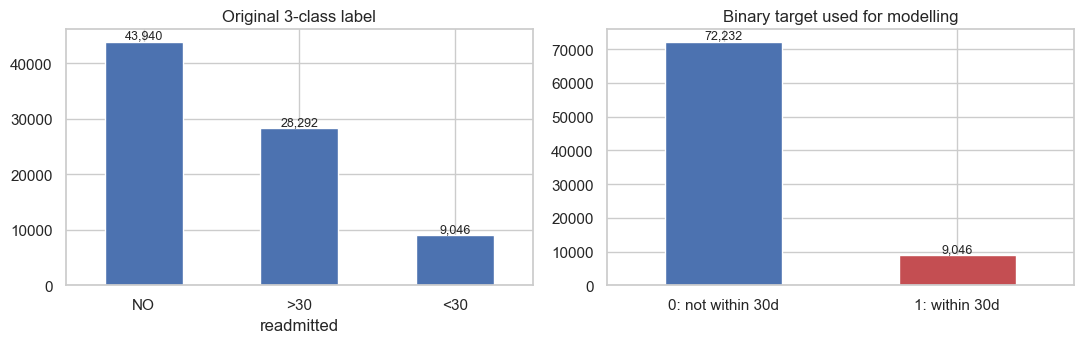

Positive class (<30 days): 11.13%  ->  imbalance ratio about 1 : 8.0


In [6]:
# Binary target: readmitted within 30 days (1) vs not (0: '>30' or 'NO')
df["target"] = (df["readmitted"] == "<30").astype(int)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
df["readmitted"].value_counts().reindex(["NO", ">30", "<30"]).plot.bar(ax=ax[0], color="#4C72B0", rot=0)
ax[0].set_title("Original 3-class label")
bin_counts = df["target"].value_counts().sort_index()
bin_counts.index = ["0: not within 30d", "1: within 30d"]
bin_counts.plot.bar(ax=ax[1], color=["#4C72B0", "#C44E52"], rot=0)
ax[1].set_title("Binary target used for modelling")
for a in ax:
    for p in a.patches:
        a.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

pos = df["target"].mean()
print(f"Positive class (<30 days): {pos:.2%}  ->  imbalance ratio about 1 : {(1 - pos) / pos:.1f}")

**Finding:** only about one encounter in nine is a 30-day readmission. A model that always answers
"no readmission" would score roughly 89 % accuracy and be useless. Later milestones must therefore be judged with
recall, precision, F1 and PR-AUC, not accuracy alone.

### 4.2 Missing values

                   n_missing  pct_missing
weight                 78695        96.82
medical_specialty      39734        48.89
payer_code             32336        39.78
race                    1777         2.19
diag_3                  1147         1.41
diag_2                   286         0.35
diag_1                    18         0.02


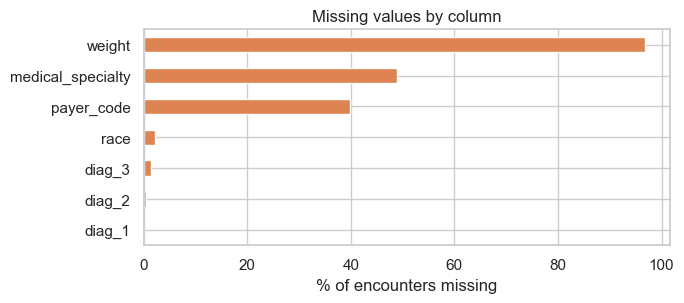


Tests 'not performed' (a real category, NOT missing):
  max_glu_serum: 94.7% are 'None'
  A1Cresult: 83.3% are 'None'


In [7]:
miss = df.isna().sum().rename("n_missing").to_frame()
miss["pct_missing"] = (miss["n_missing"] / len(df) * 100).round(2)
miss = miss[miss["n_missing"] > 0].sort_values("pct_missing", ascending=False)
print(miss.to_string())

ax = miss["pct_missing"].plot.barh(figsize=(7, 3.2), color="#DD8452")
ax.invert_yaxis(); ax.set_xlabel("% of encounters missing"); ax.set_title("Missing values by column")
plt.tight_layout(); plt.show()

print("\nTests 'not performed' (a real category, NOT missing):")
for c in ["max_glu_serum", "A1Cresult"]:
    print(f"  {c}: {(df[c] == 'None').mean():.1%} are 'None'")

### 4.3 Categorical columns, constant columns, odd values

In [8]:
cat_cols_all = df.select_dtypes(exclude="number").columns.drop("readmitted")
print("Highest-cardinality categorical columns:")
print(df[cat_cols_all].nunique().sort_values(ascending=False).head(8).to_string())

constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
print("\nConstant columns (zero information):", constant_cols)
print("Gender values:", df["gender"].value_counts().to_dict())
print("\nDischarge codes that mean death/hospice (11, 13, 14, 19, 20, 21):",
      int(df["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21]).sum()), "encounters")

Highest-cardinality categorical columns:


diag_3               764
diag_2               724
diag_1               704
medical_specialty     70
payer_code            17
age                   10
weight                 9
race                   5

Constant columns (zero information): ['examide', 'citoglipton']
Gender values: {'Female': 43817, 'Male': 37458, 'Unknown/Invalid': 3}

Discharge codes that mean death/hospice (11, 13, 14, 19, 20, 21): 1910 encounters


### 4.4 Numeric columns and outliers
Rule used to *count* outliers: a value is flagged if it lies more than 1.5 x IQR beyond the quartiles (Tukey's rule).

                     mean    std  min   1%   50%   99%    max   skew  n_outliers_IQR  pct_outliers
time_in_hospital     4.40   2.99  1.0  1.0   4.0  14.0   14.0   1.13            1796          2.21
num_lab_procedures  43.08  19.65  1.0  1.0  44.0  85.0  132.0  -0.24             103          0.13
num_procedures       1.34   1.71  0.0  0.0   1.0   6.0    6.0   1.32            3970          4.88
num_medications     16.01   8.12  1.0  3.0  15.0  43.0   81.0   1.34            2015          2.48
number_outpatient    0.37   1.28  0.0  0.0   0.0   5.0   42.0   8.88           13364         16.44
number_emergency     0.20   0.97  0.0  0.0   0.0   3.0   76.0  24.12            9080         11.17
number_inpatient     0.63   1.26  0.0  0.0   0.0   6.0   21.0   3.63            5610          6.90
number_diagnoses     7.42   1.94  1.0  2.0   8.0   9.0   16.0  -0.88             224          0.28


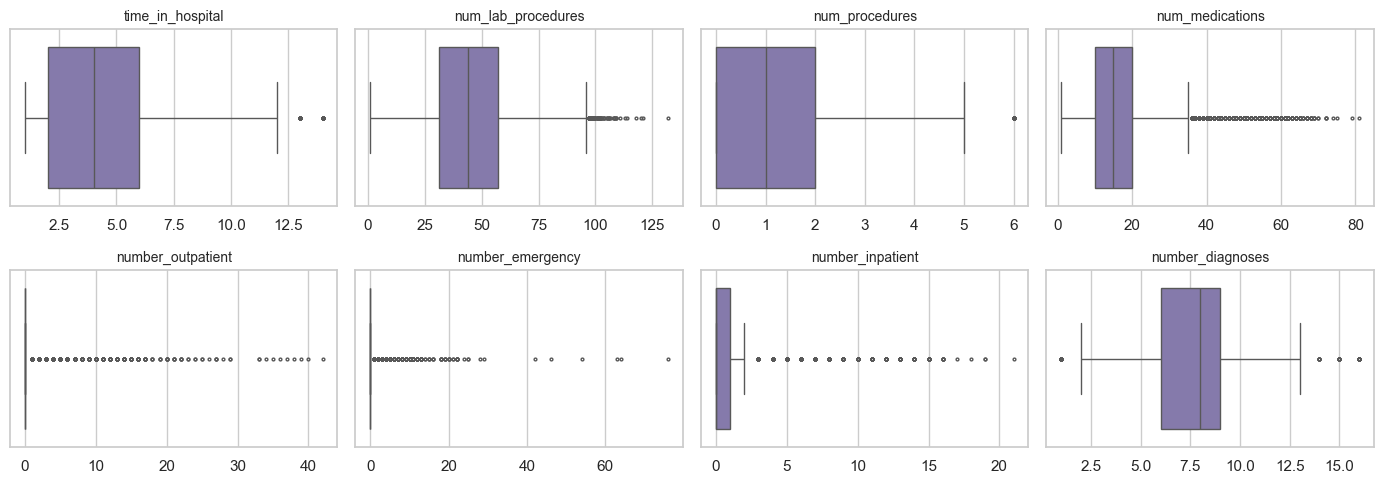

In [9]:
num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]

desc = df[num_cols].describe(percentiles=[0.01, 0.5, 0.99]).T[["mean", "std", "min", "1%", "50%", "99%", "max"]]
desc["skew"] = df[num_cols].skew()
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
desc["n_outliers_IQR"] = ((df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)).sum()
desc["pct_outliers"] = (desc["n_outliers_IQR"] / len(df) * 100).round(2)
print(desc.round(2).to_string())

fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for a, c in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[c], ax=a, color="#8172B3", fliersize=2)
    a.set_title(c, fontsize=10); a.set_xlabel("")
plt.tight_layout(); plt.show()

**Finding:** the three prior-visit counts (`number_outpatient`, `number_emergency`, `number_inpatient`) are extremely
right-skewed. Those extreme values are real, very sick, frequently hospitalised patients, who are likely to be the
readmitted ones. Deleting them would remove the signal, so in Section 5 we will *limit* their influence instead
(winsorise, then log-transform) rather than drop rows.

### 4.5 Which features move the target?

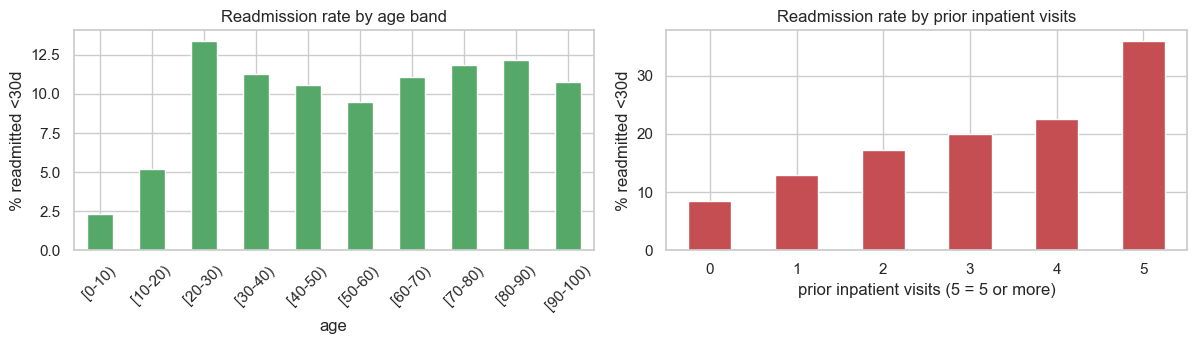

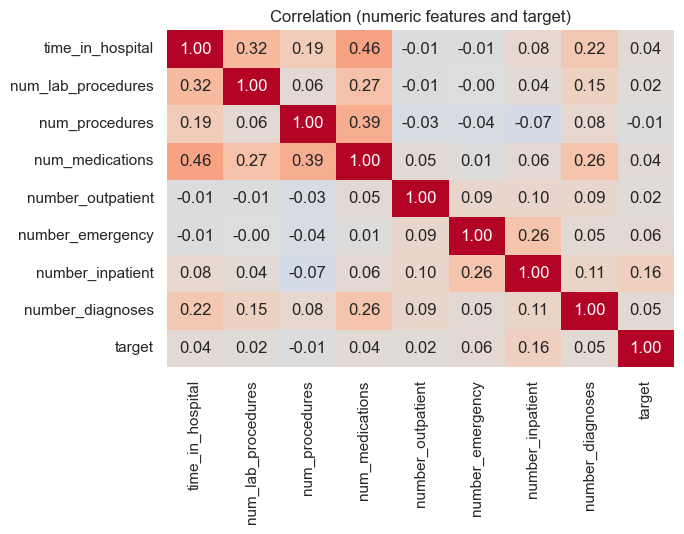

In [10]:
age_order = sorted(df["age"].unique(), key=lambda s: int(s.strip("[").split("-")[0]))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
(df.groupby("age")["target"].mean().reindex(age_order) * 100).plot.bar(ax=ax[0], color="#55A868", rot=45)
ax[0].set_ylabel("% readmitted <30d"); ax[0].set_title("Readmission rate by age band")

inp = df["number_inpatient"].clip(upper=5)
(df.groupby(inp)["target"].mean() * 100).plot.bar(ax=ax[1], color="#C44E52", rot=0)
ax[1].set_xlabel("prior inpatient visits (5 = 5 or more)"); ax[1].set_ylabel("% readmitted <30d")
ax[1].set_title("Readmission rate by prior inpatient visits")
plt.tight_layout(); plt.show()

corr = df[num_cols + ["target"]].corr().round(2)
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f", cbar=False)
plt.title("Correlation (numeric features and target)"); plt.tight_layout(); plt.show()

### 4.6 Duplicates and repeated patients

In [11]:
feature_cols = [c for c in df.columns if c not in ("encounter_id", "patient_nbr", "target")]
print("Fully identical rows (all columns)              :", int(df.duplicated().sum()))
print("encounter_id unique?                            :", df["encounter_id"].is_unique)
print("Rows identical after ignoring the two ID columns:", int(df.duplicated(subset=feature_cols).sum()))

per_patient = df.groupby("patient_nbr").size()
print(f"\nPatients: {per_patient.shape[0]:,} | encounters: {len(df):,}")
print("Encounters per patient:", per_patient.value_counts().sort_index().head(6).to_dict(), "...")
print(f"Patients with 2+ encounters: {(per_patient > 1).mean():.1%} (max {per_patient.max()})")

Fully identical rows (all columns)              : 0
encounter_id unique?                            : True
Rows identical after ignoring the two ID columns: 0

Patients: 57,214 | encounters: 81,278
Encounters per patient: {1: 43817, 2: 8364, 3: 2633, 4: 1120, 5: 605, 6: 260} ...
Patients with 2+ encounters: 23.4% (max 28)


**Decisions on duplicates:** there are no duplicate encounters, either as full rows or after ignoring the two ID columns
(and each `encounter_id` is unique), so no rows are removed. The real duplication risk is different: **repeated patients**
(a minority of patients have several stays), which would leak information between train and test if rows were split at random.
It is handled by the group-aware split in Section 5.3.

---
## 5. Pre-processing
Two kinds of steps, kept strictly apart to avoid **data leakage**:

* **Stateless cleaning** (5.1): fixes that use no statistics learned from the data, so they are safe to apply to everything.
* **Learned transforms** (5.4): winsorising limits, scaling means/SDs and category lists are *fitted on the training part only*,
  then applied unchanged to the test part.

### 5.1 Stateless cleaning, with a log of rows and columns
First, a mini-trace of the ICD-9 grouping rule on six codes (each of the three diagnosis columns has 700+ distinct codes in this subsample, far too many to one-hot encode):

In [12]:
def icd9_group(code):
    """Group an ICD-9 code into the 9 clinical categories used by Strack et al. (2014)."""
    if pd.isna(code):
        return "Missing"
    c = str(code)
    if c.startswith(("V", "E")):
        return "Other"
    i = int(float(c))                       # '250.83' -> 250
    if i == 250:                              return "Diabetes"
    if 390 <= i <= 459 or i == 785:           return "Circulatory"
    if 460 <= i <= 519 or i == 786:           return "Respiratory"
    if 520 <= i <= 579 or i == 787:           return "Digestive"
    if 580 <= i <= 629 or i == 788:           return "Genitourinary"
    if 710 <= i <= 739:                       return "Musculoskeletal"
    if 800 <= i <= 999:                       return "Injury"
    if 140 <= i <= 239:                       return "Neoplasms"
    return "Other"

trace = pd.DataFrame({"raw_code": ["250.83", "428", "786", "V57", "414", np.nan]})
trace["integer_part"] = [np.nan if pd.isna(c) else (None if str(c).startswith(("V", "E")) else int(float(c)))
                         for c in trace["raw_code"]]
trace["group"] = trace["raw_code"].map(icd9_group)
print(trace.to_string())

  raw_code  integer_part        group
0   250.83         250.0     Diabetes
1      428         428.0  Circulatory
2      786         786.0  Respiratory
3      V57           NaN        Other
4      414         414.0  Circulatory
5      NaN           NaN      Missing


In [13]:
DRUG_COLS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
             "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
             "troglitazone", "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin",
             "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]
AGE_MIDPOINT = {f"[{a}-{a + 10})": a + 5 for a in range(0, 100, 10)}
DEAD_OR_HOSPICE = [11, 13, 14, 19, 20, 21]
ID_AS_CATEGORY = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]


def clean(frame):
    log = []
    d = frame.copy()

    def step(name, before_rows, before_cols):
        log.append({"step": name, "rows_removed": before_rows - len(d),
                    "cols_removed": before_cols - d.shape[1], "rows_left": len(d), "cols_left": d.shape[1]})

    r, c = len(d), d.shape[1]
    d = d[d["gender"] != "Unknown/Invalid"]
    step("drop gender = Unknown/Invalid", r, c)

    r, c = len(d), d.shape[1]
    d = d[~d["discharge_disposition_id"].isin(DEAD_OR_HOSPICE)]
    step("drop patients who died / went to hospice (cannot be readmitted)", r, c)

    r, c = len(d), d.shape[1]
    d = d.drop(columns=["encounter_id", "weight", "readmitted"])
    step("drop encounter_id (ID), weight (97% missing), readmitted (replaced by target)", r, c)

    r, c = len(d), d.shape[1]
    share_no = {col: (d[col] == "No").mean() for col in DRUG_COLS}
    near_constant = [col for col, s in share_no.items() if s >= 0.995]
    d = d.drop(columns=near_constant)
    step(f"drop {len(near_constant)} drug columns that are >= 99.5% 'No'", r, c)

    r, c = len(d), d.shape[1]
    d["age_num"] = d["age"].map(AGE_MIDPOINT)
    d = d.drop(columns="age")
    step("age band -> numeric midpoint (age_num)", r, c)

    r, c = len(d), d.shape[1]
    for k in (1, 2, 3):
        d[f"diag_{k}_group"] = d[f"diag_{k}"].map(icd9_group)
    d = d.drop(columns=["diag_1", "diag_2", "diag_3"])
    step("ICD-9 codes -> 9 clinical groups (diag_1/2/3_group)", r, c)

    r, c = len(d), d.shape[1]
    for col in ID_AS_CATEGORY:
        d[col] = d[col].astype(str)
    for col in ["race", "payer_code", "medical_specialty"]:
        d[col] = d[col].fillna("Missing")
    step("ID codes -> categories; missing race/payer/specialty -> 'Missing' category", r, c)

    return d.reset_index(drop=True), pd.DataFrame(log), near_constant


clean_df, clean_log, near_constant = clean(df)
print(clean_log.to_string(index=False))
print("\nNear-constant drug columns dropped:", near_constant)
print("\nRemaining NaN cells:", int(clean_df.isna().sum().sum()))
print("Cleaned shape:", clean_df.shape)

                                                                         step  rows_removed  cols_removed  rows_left  cols_left
                                                drop gender = Unknown/Invalid             3             0      81275         51
              drop patients who died / went to hospice (cannot be readmitted)          1910             0      79365         51
drop encounter_id (ID), weight (97% missing), readmitted (replaced by target)             0             3      79365         48
                                  drop 13 drug columns that are >= 99.5% 'No'             0            13      79365         35
                                       age band -> numeric midpoint (age_num)             0             0      79365         35
                          ICD-9 codes -> 9 clinical groups (diag_1/2/3_group)             0             0      79365         35
   ID codes -> categories; missing race/payer/specialty -> 'Missing' category             0             

**Why these choices**

| Issue | Decision | Reason |
|---|---|---|
| `weight` ~97 % missing | drop column | Nothing reliable to impute from |
| `race`, `payer_code`, `medical_specialty` missing | new category `"Missing"` | Missingness can itself be informative (e.g. specialty not recorded), and imputing a person's race would be guesswork and ethically poor |
| `max_glu_serum`, `A1Cresult` = `None` | keep as a category | It means "test not performed", a clinical signal |
| 700+ distinct codes in each of 3 diagnosis columns | group into 9 clinical categories | Keeps the information, avoids ~2,200 sparse columns |
| Death / hospice discharge | remove rows | These patients cannot be readmitted, so labelling them "not readmitted" would teach the model something false |
| Near-constant drugs, ID columns | drop | No usable information, or an identifier that would only invite over-fitting |
| Prior-visit counts with extreme values | keep rows, limit influence later | Extreme values are genuine, informative cases |

### 5.2 Features and target

In [14]:
y = clean_df["target"]
groups = clean_df["patient_nbr"]
X = clean_df.drop(columns=["target", "patient_nbr"])     # patient_nbr is kept ONLY for grouping, never as a feature

NUM_STD = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
           "number_diagnoses", "age_num"]
NUM_SKEW = ["number_outpatient", "number_emergency", "number_inpatient"]
CAT = [c for c in X.columns if c not in NUM_STD + NUM_SKEW]

print(f"{X.shape[1]} features: {len(NUM_STD)} numeric + {len(NUM_SKEW)} skewed-count + {len(CAT)} categorical")
print("Categorical:", CAT)

33 features: 6 numeric + 3 skewed-count + 24 categorical
Categorical: ['race', 'gender', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'insulin', 'glyburide-metformin', 'change', 'diabetesMed', 'diag_1_group', 'diag_2_group', 'diag_3_group']


### 5.3 Train / test split (group-aware, stratified, seeded)
`StratifiedGroupKFold(n_splits=5)` takes ~20 % of the **patients** for the test set, keeps the class ratio close to the
overall one, and guarantees no patient appears on both sides.

In [15]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[train_idx].reset_index(drop=True), X.iloc[test_idx].reset_index(drop=True)
y_train, y_test = y.iloc[train_idx].reset_index(drop=True), y.iloc[test_idx].reset_index(drop=True)

overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
assert len(overlap) == 0
print(f"Train: {len(X_train):,} encounters / {groups.iloc[train_idx].nunique():,} patients | positive rate {y_train.mean():.2%}")
print(f"Test : {len(X_test):,} encounters / {groups.iloc[test_idx].nunique():,} patients | positive rate {y_test.mean():.2%}")
print("Patients present in BOTH train and test:", len(overlap))

Train: 63,490 encounters / 44,869 patients | positive rate 11.35%
Test : 15,875 encounters / 11,148 patients | positive rate 11.36%
Patients present in BOTH train and test: 0


### 5.4 Learned transforms: winsorise, log, scale, one-hot (fit on train only)
* **Winsorising** clips each numeric column to its 1st-99th percentile (limits learned on train) to tame outliers without deleting rows.
* **log(1 + x)** for the three heavy-tailed visit counts, then **standardisation** (mean 0, SD 1), so distance- and gradient-based models are not dominated by large-scale columns.
* **One-hot encoding** for categories; categories under 1 % are pooled into one "infrequent" bucket (learned on train), and unseen test categories are handled safely.

In [16]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each column to [lower, upper] quantiles learned in fit()."""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_ = np.quantile(X, self.lower, axis=0)
        self.hi_ = np.quantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


num_std_pipe = Pipeline([("winsor", Winsorizer()), ("scale", StandardScaler())])
num_skew_pipe = Pipeline([("winsor", Winsorizer()),
                          ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                          ("scale", StandardScaler())])
cat_pipe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False)

preprocessor = ColumnTransformer([("num", num_std_pipe, NUM_STD),
                                  ("skew", num_skew_pipe, NUM_SKEW),
                                  ("cat", cat_pipe, CAT)], verbose_feature_names_out=False)

X_train_p = pd.DataFrame(preprocessor.fit_transform(X_train), columns=preprocessor.get_feature_names_out())
X_test_p = pd.DataFrame(preprocessor.transform(X_test), columns=preprocessor.get_feature_names_out())

print("Train matrix:", X_train_p.shape, "| Test matrix:", X_test_p.shape)
print("NaN left (train/test):", int(X_train_p.isna().sum().sum()), "/", int(X_test_p.isna().sum().sum()))
print("\nScaled numeric columns, TRAIN (mean should be ~0, SD ~1):")
print(X_train_p[NUM_STD + NUM_SKEW].agg(["mean", "std"]).round(3).T.to_string())
print("\nSame columns, TEST (close to, but not exactly, 0 and 1: proof we did not peek):")
print(X_test_p[NUM_STD + NUM_SKEW].agg(["mean", "std"]).round(3).T.to_string())

Train matrix: (63490, 132) | Test matrix: (15875, 132)
NaN left (train/test): 0 / 0

Scaled numeric columns, TRAIN (mean should be ~0, SD ~1):
                    mean  std
time_in_hospital    -0.0  1.0
num_lab_procedures  -0.0  1.0
num_procedures       0.0  1.0
num_medications     -0.0  1.0
number_diagnoses     0.0  1.0
age_num              0.0  1.0
number_outpatient    0.0  1.0
number_emergency    -0.0  1.0
number_inpatient     0.0  1.0

Same columns, TEST (close to, but not exactly, 0 and 1: proof we did not peek):
                     mean    std
time_in_hospital   -0.004  0.999
num_lab_procedures -0.013  0.999
num_procedures     -0.001  1.001
num_medications    -0.013  0.990
number_diagnoses    0.001  1.007
age_num            -0.020  0.999
number_outpatient   0.009  1.004
number_emergency   -0.007  0.980
number_inpatient    0.009  1.000


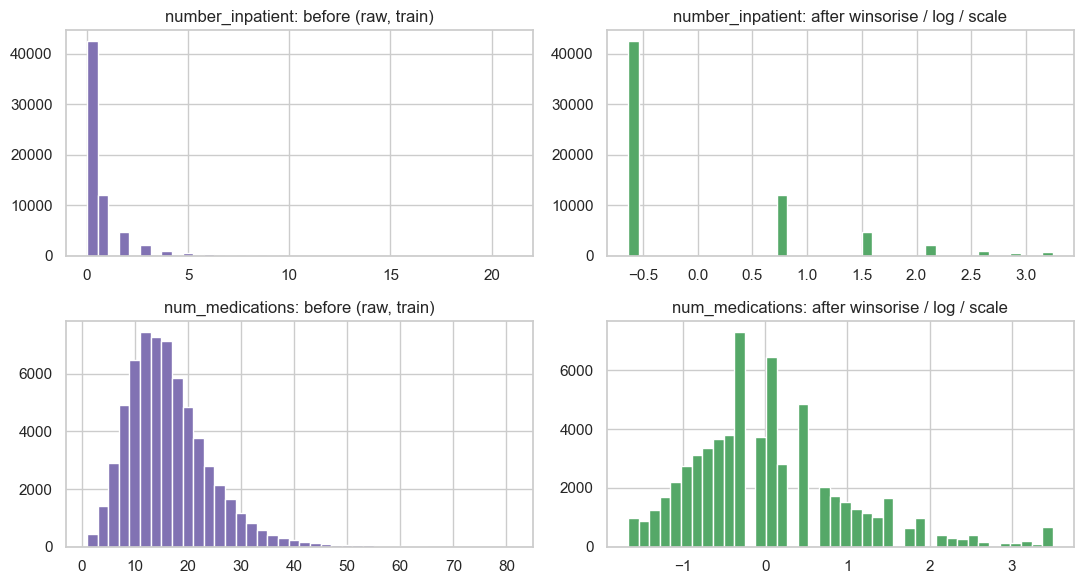

Skewness before -> after:
  number_outpatient      9.30 ->   2.45
  number_emergency      24.34 ->   2.98
  number_inpatient       3.58 ->   1.37
  num_medications        1.35 ->   0.98


In [17]:
fig, ax = plt.subplots(2, 2, figsize=(11, 6))
for row, col in enumerate(["number_inpatient", "num_medications"]):
    ax[row, 0].hist(X_train[col], bins=40, color="#8172B3")
    ax[row, 0].set_title(f"{col}: before (raw, train)")
    ax[row, 1].hist(X_train_p[col], bins=40, color="#55A868")
    ax[row, 1].set_title(f"{col}: after winsorise / log / scale")
plt.tight_layout(); plt.show()

print("Skewness before -> after:")
for col in NUM_SKEW + ["num_medications"]:
    print(f"  {col:20s} {X_train[col].skew():6.2f} -> {X_train_p[col].skew():6.2f}")

### 5.5 Final check and saved outputs

In [18]:
os.makedirs("processed", exist_ok=True)
X_train_p.to_csv("processed/X_train.csv.gz", index=False)
X_test_p.to_csv("processed/X_test.csv.gz", index=False)
y_train.to_csv("processed/y_train.csv", index=False)
y_test.to_csv("processed/y_test.csv", index=False)

summary = {
    "student_id": STUDENT_ID,
    "seed": SEED,
    "subsample_method": "stratified 80% of patients, all encounters kept",
    "subsample_fingerprint": fingerprint[:16] + "...",
    "patients_in_subsample": len(kept_ids),
    "encounters_in_subsample": len(df),
    "encounters_after_cleaning": len(clean_df),
    "features_before_encoding": X.shape[1],
    "features_after_encoding": X_train_p.shape[1],
    "train_rows": len(X_train_p),
    "test_rows": len(X_test_p),
    "positive_rate_train": round(float(y_train.mean()), 4),
    "positive_rate_test": round(float(y_test.mean()), 4),
}
for k, v in summary.items():
    print(f"{k:28s}: {v}")
assert len(X_train_p) + len(X_test_p) >= 1000

student_id                  : SH2301468
seed                        : 2301468
subsample_method            : stratified 80% of patients, all encounters kept
subsample_fingerprint       : 159456edbd794ca8...
patients_in_subsample       : 57214
encounters_in_subsample     : 81278
encounters_after_cleaning   : 79365
features_before_encoding    : 33
features_after_encoding     : 132
train_rows                  : 63490
test_rows                   : 15875
positive_rate_train         : 0.1135
positive_rate_test          : 0.1136


## 6. What Milestone 2 will build on
* Models will be trained **only** on `processed/X_train.csv.gz`, evaluated on the untouched test set.
* Class imbalance (about 1 : 8) will be handled **inside** cross-validation on the training data (class weights or resampling), never before the split.
* Cross-validation will use `StratifiedGroupKFold` on patient IDs, as here.
* Metrics: recall, precision, F1, PR-AUC and ROC-AUC, not accuracy alone.